# 环境导入

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display, HTML


# 关闭坐标轴负号的特殊显示（否则负号会渲染成方块）
plt.rcParams['axes.unicode_minus'] = False

# 按优先级排列的候选常用中文字体名
_cjk_candidates = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Noto Sans CJK SC',
                  'Arial Unicode MS', 'WenQuanYi Micro Hei', 'Source Han Sans SC']

# 最终选中的字体名；初始为 None 表示还没找到
_chosen = None

# 第一轮：按优先级逐个检查候选字体是否存在
for _name in _cjk_candidates:
    try:
        # findfont 能成功返回，说明系统安装了该字体
        fm.findfont(_name, fallback_to_default=False)
        # 记录第一个可用字体并结束查找
        _chosen = _name
        break
    except Exception:
        # 该字体未安装，跳过并尝试下一个候选
        continue

# 兜底：候选全都没命中时，扫描系统已安装的全部字体
if _chosen is None:
    # 判断一个字体"像中文字体"的关键词列表
    _font_keywords = ('YaHei', 'SimHei', 'Hei', 'CJK', 'PingFang',
                      'WenQuanYi', 'Noto Sans CJK', 'Song', 'Kai', 'Ming')
    # 逐个检查系统字体列表
    for _f in fm.fontManager.ttflist:
        # 当前字体名是否包含任一中文关键词（初始认为不是）
        _is_cjk_like = False
        for _k in _font_keywords:
            if _k in _f.name:
                # 命中关键词，判定该字体可显示中文
                _is_cjk_like = True
                break
        if _is_cjk_like:
            # 取第一个命中的字体作为中文字体并结束扫描
            _chosen = _f.name
            break

# 应用最终选定的字体，并把结果告诉用户
if _chosen:
    plt.rcParams['font.sans-serif'] = [_chosen]
    print(f'中文字体: {_chosen}')
else:
    print('警告: 未找到中文字体，图表中文可能显示为方块')
%matplotlib inline


# ═══════════════════════════════════════════════════
# 路径引导：让 Notebook 能导入 src 包，并正确定位项目根目录
# ═══════════════════════════════════════════════════
import sys
from pathlib import Path

# Notebook 就在项目根目录下运行 → 当前工作目录即项目根目录；
# 若日后再放进 notebooks/ 子目录，则取上一层（保留这层兼容判断）
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 后续所有 cell 统一用 `from src.xxx import ...` 导入；
# 数据 / 结果路径由 src/config.py 集中管理（与命令行入口共用同一套路径）
from src.config import DATA_DIR, RESULTS_DIR

print(f'项目根目录: {PROJECT_ROOT}')
print(f'数据目录  : {DATA_DIR}')
print(f'结果目录  : {RESULTS_DIR}')


中文字体: Microsoft YaHei
项目根目录: D:\Code\ecommerce-user-behavior-segmentation
数据目录  : D:\Code\ecommerce-user-behavior-segmentation\data
结果目录  : D:\Code\ecommerce-user-behavior-segmentation\results


# EDA探索性数据分析

## 数据加载与预处理

数据源为 7 个月用户面板（`data/panel_7months.parquet`，user_id 哈希抽样 5%，约 78 万用户）。取 **10 月事件**用于建模/EDA，**11 月事件**用于验证。


In [2]:
# ============================================================
# 数据加载：只读 7 个月面板中的 10 月
# （面板是全量 7 个月，这里按月份行过滤，避免读入全量数据）
# → 10 月事件用于建模 / EDA / 分层；
#   11 月事件只在后面「各人群 11 月转化率对比（购买力/价值）」单元用到，
#   那里从已载入的 7 个月面板 panel_all 里取，不在这里提前读入
# ============================================================

# 从配置读取面板文件路径
from src.config import PANEL_FILE
# 从 analysis 导入：面板读取函数 + 用户级特征构建函数
from src.analysis import load_panel, build_features

# 加载 10 月的事件数据（只读建模月，避免读全量）
oct_events = load_panel(PANEL_FILE, months=['2019-10'])

# 输出 10 月事件条数
print(f"10月事件数: {len(oct_events)} 条")

# 与 analysis.py 共用同一套特征构建逻辑（单一事实来源）
# 截止时刻取该月最后一条事件的时间，保证特征口径与线上一致
oct_cutoff = oct_events['event_time'].max()
df = build_features(oct_events, oct_cutoff)

# 输出用户级特征表的规模：多少用户 × 多少特征
print(f"\n用户级特征表: {df.shape[0]} 用户 × {df.shape[1]} 特征")
df.head()


10月事件数: 2117423 条

用户级特征表: 151447 用户 × 12 特征


,user_id,Purchase_Frequency,Total_Spending,Pages_Viewed,Session_Count,Estimated_Time,Cart_Products,Purchased_Products,Recency_Days,Activity,Friction,Log_Friction
0,231943435,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
1,240236728,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
2,241587569,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0
3,278266184,0,0.0,28,14,1129.0,0,0,31,1.630707,0,0.0
4,290749523,0,0.0,1,1,0.0,0,0,31,-1.089410,0,0.0


## 10月份数据总览

In [3]:
# ============================================================
# 数值特征概览：描述性统计 + 缺失值检查 + 偏度
# （判断各特征是否存在长尾 / 缺失，为后续变换做准备）
# ============================================================

# 参与数值统计的目标特征列（与后续建模口径保持一致）
target_numeric = ['Recency_Days', 'Purchase_Frequency', 'Total_Spending',
                  'Pages_Viewed', 'Estimated_Time', 'Cart_Products']



# 统计整张特征表的缺失值总数
miss = df.isnull().sum().sum()

# 根据缺失情况拼提示文案：无缺失显示 ✅，有缺失则显示具体个数
if miss == 0:
    miss_msg = '✅ 无缺失'
else:
    miss_msg = f'⚠️ {miss} 个'
print(f"缺失值: {miss_msg}\n")

# 对数值特征做描述性统计
summary = df[target_numeric].describe().T.round(2)
# 追加一列：各特征的偏度（|偏度| 越大说明分布越右偏/长尾）
summary['skew'] = df[target_numeric].skew().round(2)

display(summary)


缺失值: ✅ 无缺失



,count,mean,std,min,25%,50%,75%,max,skew
Recency_Days,151447.0,28.98,6.33,0.0,31.0,31.0,31.0,31.00,-3.21
Purchase_Frequency,151447.0,0.25,1.54,0.0,0.0,0.0,0.0,291.00,60.16
Total_Spending,151447.0,76.71,700.57,0.0,0.0,0.0,0.0,84781.78,50.47
Pages_Viewed,151447.0,13.42,30.75,0.0,2.0,4.0,13.0,2312.00,12.81
Estimated_Time,151447.0,714.79,1798.03,0.0,0.0,149.0,685.0,141713.00,12.71
Cart_Products,151447.0,0.17,0.61,0.0,0.0,0.0,0.0,21.00,7.73


### 10月份数据总览解读：

1. **未购用户占比很高，需要先区分已购和未购用户**

    - 在 151,447 名用户中，有 133,927 人从未购买过，占比 88.4%；
    - 有过购买行为的用户仅占 11.6%。

    如果直接对所有用户，根据最近购买时间、购买频次和消费金额进行 RFM 聚类划分，由于大部分用户的购买频次和消费金额都是 0，聚类结果很容易集中在“从未购买”的一类，难以进一步区分不同用户的价值。因此，项目决定先将用户分为已购和未购两组，再分别进行细分。
2. **某些特征差异巨大，要先处理极端值**

    用户的消费金额和购买频次都呈现明显的长尾分布：大部分用户的数值很低，少数用户却非常高。例如，Total_Spending（总消费金额）的偏度约为 50，Purchase_Frequency（购买频次）的偏度约为 60。这意味着，少数高消费、高频次用户可能会影响用户分层的效果，固定数值区间或简单按分位数划分也不一定合适。因此，后续先对相关指标使用 log1p 变换（ln(1+x)），缩小极端值与普通用户之间的差距，再通过 GMM高斯混合模型动态识别用户群体的分界点，让分层更贴合实际数据分布。


### 10月份单变量分布可视化

之前的描述统计显示，部分变量存在明显的长尾现象（偏度约为 50～60）。为了更直观地了解各指标的分布情况，这里通过直方图对比原始值和 log1p 变换后的分布。

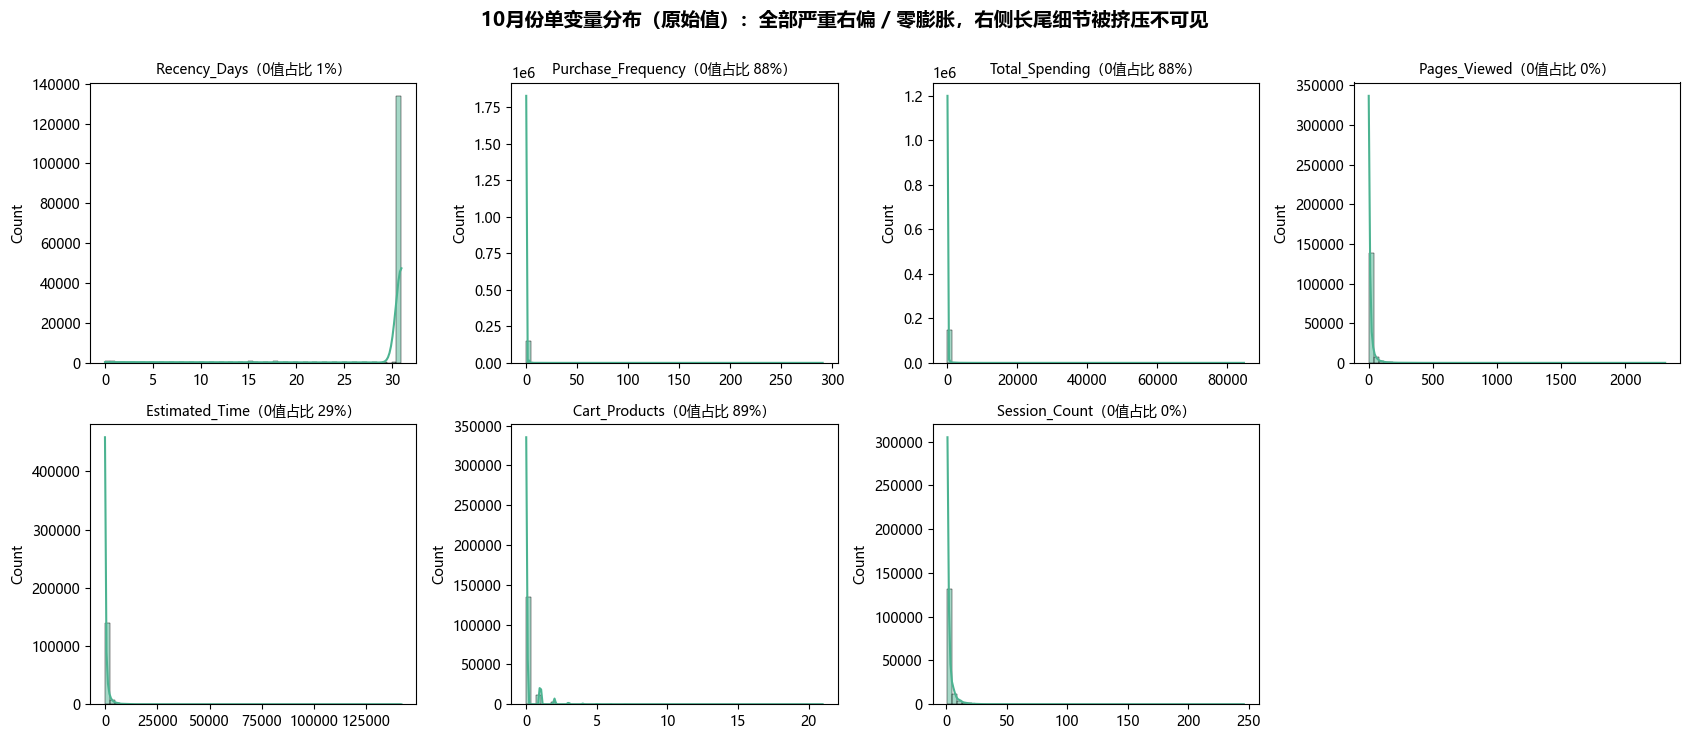

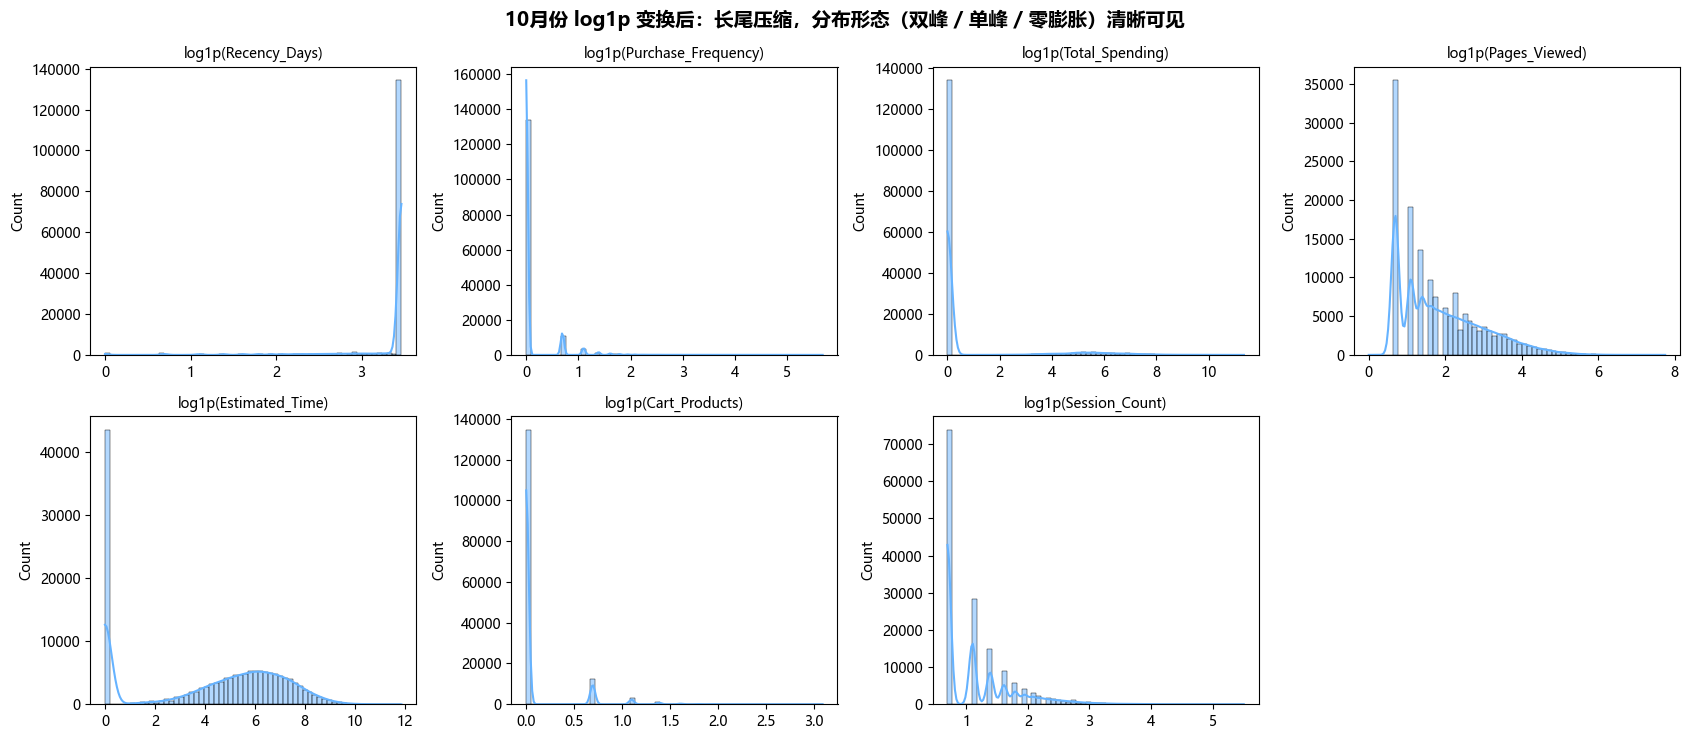

In [4]:
# ═══════════════════════════════════════════════════
# 单变量分布：原始值 vs log1p 变换（印证长尾 / 零膨胀）
# ═══════════════════════════════════════════════════
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 要画分布图的列：与数值特征一致的 7 个变量
# （target_numeric 6 个 + Session_Count 会话数，相关分析里也用这一组）
plot_cols = target_numeric + ['Session_Count']
# 变量个数（画 2x4 子图网格，实际只用到前 7 格）
n = len(plot_cols)

# ── 图 1：原始值分布（全范围）──
# 画图意图：展示"未做任何变换"时各变量的分布形态，
# 预期看到严重右偏 / 大量 0 堆积，右侧长尾细节被挤压不可见
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, plot_cols):
    # 数值先截断到非负，避免负数干扰分布形态
    v = df[col].clip(lower=0)
    # 统计该变量中等于 0 的占比，用于标注"零膨胀"程度
    zero_pct = (v == 0).mean()
    # 画直方图 + 核密度曲线
    sns.histplot(v, bins=60, ax=ax, color='#4CB391', kde=True)
    # 标题标注变量名与 0 值占比
    ax.set_title(f'{col}（0值占比 {zero_pct:.0%}）', fontsize=10)
    ax.set_xlabel('')
# 关掉多余的空白子图（第 8 格没有数据）
for ax in axes[n:]:
    ax.axis('off')
# 整图大标题，说明图 1 要表达的核心信息
plt.suptitle('10月份单变量分布（原始值）：全部严重右偏 / 零膨胀，右侧长尾细节被挤压不可见',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── 图 2：log1p 变换后的分布（长尾压缩后形态可见）──
# 画图意图：对数值取 log1p（log(1+x)）压缩长尾，
# 让原本被挤压不可见的分布形态（双峰 / 单峰 / 零膨胀）显形
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, plot_cols):
    # 先 clip 到非负再 log1p 变换（避免对负值取对数）
    log1p_vals = np.log1p(df[col].clip(lower=0))
    # 画变换后值的直方图 + 核密度曲线
    sns.histplot(log1p_vals, bins=60, ax=ax, color='#66b3ff', kde=True)
    ax.set_title(f'log1p({col})', fontsize=10)
    ax.set_xlabel('')
# 关掉多余的空子图
for ax in axes[n:]:
    ax.axis('off')
# 整图大标题，说明图 2 要表达的核心信息
plt.suptitle('10月份 log1p 变换后：长尾压缩，分布形态（双峰 / 单峰 / 零膨胀）清晰可见',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [5]:
# ═══════════════════════════════════════════════════
# 偏度量化对比：原始值 vs log1p 变换后（判断长尾是否还需进一步处理）
# ═══════════════════════════════════════════════════


# 准备 log1p 变换后的数据：clip 下限 0 避免对 0/负数取对数
log1p_vals = np.log1p(df[plot_cols].clip(lower=0))
# 原始数据同样截断到非负，仅用于统计 0 值占比
clipped_vals = df[plot_cols].clip(lower=0)

# 构建对比表：每行一个特征，三列分别对比"原始偏度 / log1p 后偏度 / 0 值占比"
skew_table = pd.DataFrame({
    '原始偏度': df[plot_cols].skew().round(2),
    'log1p后偏度': log1p_vals.skew().round(2),
    '0值占比': (clipped_vals == 0).mean().round(3),
})


def grade_skew(absolute_skew):
    # 按 |偏度| 大小划分三个等级
    if absolute_skew < 1:
        return '近似对称(<1)'
    elif absolute_skew <= 2:
        return '中等偏(1~2)'
    else:
        return '严重偏(>2)'


# 新增一列：按 log1p 后偏度的绝对值标注偏度等级
skew_table['偏度等级(log1p后)'] = skew_table['log1p后偏度'].abs().map(grade_skew)
# 以 HTML 表格形式展示对比表
display(HTML(skew_table.to_html()))



,原始偏度,log1p后偏度,0值占比,偏度等级(log1p后)
Recency_Days,-3.21,-4.66,0.005,严重偏(>2)
Purchase_Frequency,60.16,3.87,0.884,严重偏(>2)
Total_Spending,50.47,2.69,0.884,严重偏(>2)
Pages_Viewed,12.81,0.83,0.000,近似对称(<1)
Estimated_Time,12.71,-0.35,0.287,近似对称(<1)
Cart_Products,7.73,3.32,0.889,严重偏(>2)
Session_Count,6.84,1.47,0.000,中等偏(1~2)


**log1p 变换效果评估**

对各指标进行 log1p 变换后，偏度的变化并不完全相同，说明这种处理对不同类型的数据有不同的效果。

- 页数、时长和会话相关指标： 变换效果比较明显。偏度分别从 12.8、12.7、6.8 降至 0.8、-0.4、1.5，分布明显更加对称，原本突出的长尾得到了有效压缩。

- 购买频次、消费金额和加购商品数： 变换后仍然存在明显的偏度（偏度仍大于 2）。主要原因是这些指标中 0 值占比超过 88%，大量用户集中在 0 附近。log1p 可以压缩非零数值的差距，却无法消除这种由大量 0 值造成的分布特征。这反映的是用户普遍没有购买或加购行为的实际情况，并不只是数值尺度的问题。

- Recency_Days（距最近购买的天数）： 变换后负偏度从 -3.2 增大到 -4.7，分布反而更加不对称。这与该指标的取值范围较窄、且大量未购用户集中在 31 天的兜底值有关。log1p 改变了不同数值之间的间距，却没有消除这种集中现象。不过，后续价值指数采用分位数进行划分，对偏度的敏感程度相对较低，因此这一变化预计不会造成明显影响。

**结论**：考虑到后续分析使用 GMM 识别分组边界、逻辑回归（LR）进行排序，以及分位数进行分层，当前没有必要仅为了追求更低的偏度而进一步变换数据。需要注意的是，这些方法并不都要求输入数据服从正态分布，但仍需结合模型拟合效果和实际分层结果进行验证。若后续改用对数据尺度、距离或分布假设更敏感的方法，再考虑有针对性地处理。

## 10月份多变量相关分析

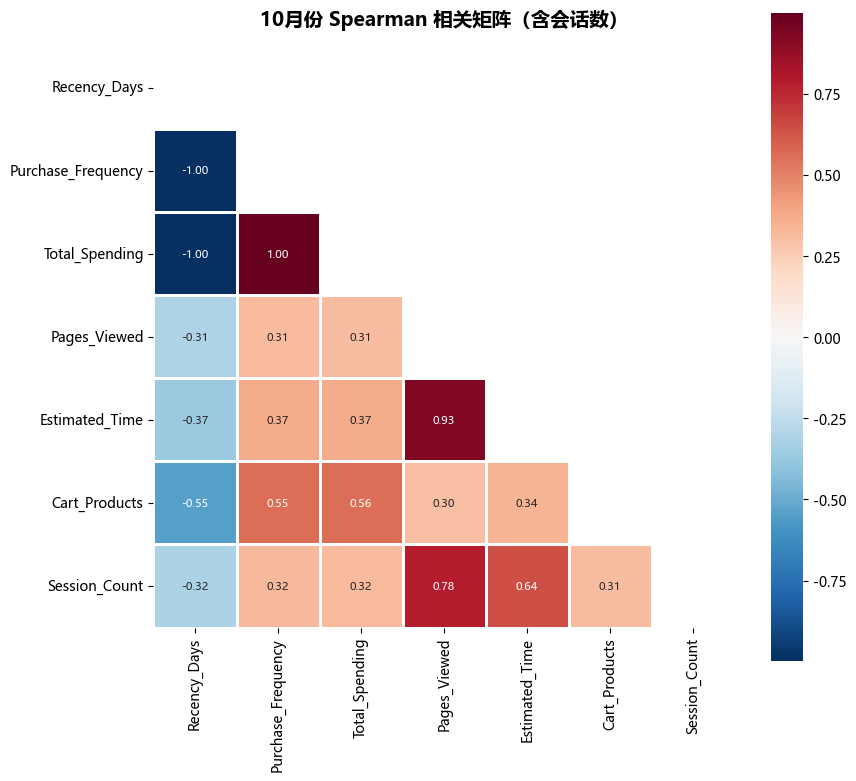

浏览三指标相关（Spearman）: 页数↔时长 r=0.925 | 页数↔会话 r=0.782 | 时长↔会话 r=0.643
加购 vs 浏览（Spearman）: r=0.303 → Friction 是与浏览独立的意图维度
未购用户占比: 88.4% | 消费偏度 50.5 | 频次偏度 60.2


In [6]:
# ============================================================
# 3a. 相关性分析：Spearman 相关热力图 + 关键相关系数
# 相关矩阵要包含会话数，是因为会话数与页数/时长同属"活跃度"指标
# ============================================================

# 参与相关分析的列：target_numeric 6 个数值特征 + 会话数
corr_cols = target_numeric + ['Session_Count']

# 准备画布（热力图用 9x8 的方形画布）
plt.figure(figsize=(9, 8))
# 计算这些特征的 Spearman 秩相关系数矩阵（对非线性单调关系更稳健）
corr = df[corr_cols].corr(method='spearman')
# 生成上三角掩码：只显示矩阵的下三角，避免重复展示对称的上半部分
mask = np.triu(np.ones_like(corr, dtype=bool))
# 画热力图：掩掉上三角、格子内标注相关系数、红蓝配色（RdBu_r）、中心色 0
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.8, annot_kws={'fontsize': 8})
# 图标题：说明该矩阵包含会话数
plt.title('10月份 Spearman 相关矩阵（含会话数）', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ── 关键相关系数（均为 Spearman，与热力图格子数值一致）──
import numpy as np

# 预先把要用到的浏览三指标两两相关系数算出来（与热力图同一口径）
r_pages_time = df["Pages_Viewed"].corr(df["Estimated_Time"], method="spearman")
r_pages_sess = df["Pages_Viewed"].corr(df["Session_Count"], method="spearman")
r_time_sess = df["Estimated_Time"].corr(df["Session_Count"], method="spearman")
# 打印浏览三指标的两两相关（页数↔时长 / 页数↔会话 / 时长↔会话）
print(f'浏览三指标相关（Spearman）: 页数↔时长 r={r_pages_time:.3f} | '
      f'页数↔会话 r={r_pages_sess:.3f} | '
      f'时长↔会话 r={r_time_sess:.3f}')

# 加购与浏览的相关性（验证 Friction 是否是独立于浏览的意图维度）
r_cart_pages = df["Cart_Products"].corr(df["Pages_Viewed"], method="spearman")
print(f'加购 vs 浏览（Spearman）: r={r_cart_pages:.3f} → Friction 是与浏览独立的意图维度')

# 汇总行级指标：未购用户占比 + 消费/频次的偏度
no_purchase_share = (df["Purchase_Frequency"] == 0).mean()
spend_skew = df["Total_Spending"].skew()
freq_skew = df["Purchase_Frequency"].skew()
print(f'未购用户占比: {no_purchase_share:.1%} | 消费偏度 {spend_skew:.1f} | '
      f'频次偏度 {freq_skew:.1f}')


### 相关分析解读：指标构建的依据

为了分析各指标之间的关系，本项目使用 **Spearman 秩相关系数**构建相关矩阵。与直接比较数值大小的 Pearson 相关不同，Spearman 先将数值转换为排名，再衡量变量之间的变化趋势是否一致。因此，它受极端值具体大小的影响相对较小，也不会因为 log1p 这类保持排名顺序的单调变换而改变相关结果。以下结论均来自 Spearman 相关矩阵。

- **浏览相关指标之间存在较多重复信息**：浏览页数与停留时长的相关系数约为 0.93，浏览页数与会话指标约为 0.78，停留时长与会话指标约为 0.64。这说明三者之间存在不同程度的关联，尤其是浏览页数与停留时长，反映的信息高度重叠。因此，可以考虑将它们合并为一个综合的 **Activity（活跃度）**指标，减少多个相关变量重复参与后续分析的情况。

- **加购行为与浏览行为的相关性较弱，可以作为独立的行为维度保留。** 加购指标与浏览相关指标的相关系数约为 0.30，说明两者存在一定关联，但反映的信息并不完全相同。因此，在构建用户分层指标时，可以保留加购行为，用于补充描述用户的行为特征。至于加购是否能够有效识别未购用户的首购潜力，还需要进一步比较有无加购用户的后续首购转化率，验证其与实际购买结果之间的关系。

- **在已购用户内部，消费金额、购买频次和近度能够提供一定程度的互补信息。**：消费金额与购买频次的相关系数约为 0.53，说明购买次数较多的用户通常也可能有更高的消费金额，但两者并非完全重复。购买频次与最近购买天数的相关系数约为 −0.22，关联相对较弱，说明购买频次较高并不一定意味着最近也有购买行为。因此，将消费金额、购买频次和近度作为不同维度构建用户价值指数具有一定依据。若采用等权合成，还需要统一各指标的尺度，并调整近度的方向（距上次购买天数越少，价值表现越好），再结合实际分层结果检验其合理性。


# 定义指标

本节介绍由 `analysis.Friction_and_Activity` 提供的三个指标，说明它们分别衡量什么，以及在后续用户分析中的用途。

1. **活跃度 Activity：衡量用户的浏览与互动深度**

   综合浏览页数、有效停留时长和会话数三个指标。有效停留时长是指在同一会话内，将相邻事件间隔小于 30 分钟的活跃时间累计起来。三个指标分别经过 `log1p` 变换和标准化后取均值，得到综合活跃度，用于描述用户在网站上的浏览与互动情况。

2. **摩擦 Friction：衡量加购后未完成购买的情况**

   通过加购但未购买的去重商品数来衡量，按 `Cart_Products − Purchased_Products` 计算，再进行 `log1p` 变换。该指标主要用于未购用户，帮助识别有过加购行为、但尚未完成购买的用户，为进一步分析其首购潜力提供参考。

3. **跨月沉默 `silent_buyer`：识别已购用户的流失风险**

   对基期的高价值买家，如果其在观察月内没有任何浏览、加购或购买行为，即完全没有再次访问或活动，则通过 `silent_buyer` 标记。该指标用于识别跨月完全沉默的高价值用户，为后续流失判定提供依据。

**数据来源与实现说明：** Activity 和 Friction 已在 「数据加载与预处理」的 `build_features` 中完成计算。本节仅解释各指标的业务含义，不重复实现计算；下方仅预览这两列特征的结果。

In [7]:

# 取出每个用户的行为意图指标（连同 user_id 一起展示，便于对号入座）
intent_preview = df[['user_id', 'Activity', 'Friction']]
# 展示前几行确认字段已生成
intent_preview.head()


,user_id,Activity,Friction
0,231943435,-1.089410,0
1,240236728,-1.089410,0
2,241587569,-1.089410,0
3,278266184,1.630707,0
4,290749523,-1.089410,0


# 用户分层

## 分层规则
本项目不对所有用户使用同一套分层规则，而是先根据用户在当前分析月份是否发生购买行为进行分流，再针对不同人群采用不同的识别方法。最终形成三类分析路径：识别未购用户的潜在转化机会、区分已购用户的价值和特点，以及识别高价值用户的跨月沉默风险。

### 当月未购用户：识别高潜力转化人群

对于当月没有购买记录的用户，使用两个行为指标进行识别：

- **活跃度（`Activity`）**：综合浏览页数、有效停留时长和会话数，衡量用户在网站上的活跃程度。
- **摩擦（`Log_Friction`）**：根据加购但未购买的去重商品数计算，用于反映用户是否存在加购未转化的行为。

分别对这两个指标使用双成分高斯混合模型（GMM）确定分界阈值。**只有当用户的活跃度和加购摩擦都达到各自阈值时，才会被标记为“高潜力首购用户”**；未满足两个条件的当月未购用户则归入“普通浏览用户”。


### 当月已购用户：识别高价值用户并进一步细分

对于当月发生过购买的用户，先计算价值指数：


\begin{aligned}
Value\_Index={}&\log(1+Total\_Spending)\\
&+\log(1+Purchase\_Frequency)\\
&-\log(1+Recency\_Days)
\end{aligned}


该指数综合考虑消费金额、购买频次和最近购买时间。其中，距最近购买的天数越长，价值指数受到的扣减越大。

接着，只在当月已购用户内部，以价值指数的第 75 百分位数（Q3）作为高价值分界线，将用户分为两组：

- **常规已购用户**：价值指数未达到高价值分界线。
- **高价值用户**：价值指数达到或超过高价值分界线，即当月已购用户中价值指数排名靠前的约 25%。

对高价值用户，再根据活跃度进行细分。代码使用 GMM 在高价值人群内部确定活跃度阈值：

- **深度互动用户**：这类用户的价值指数同样位于已购用户的前 25%，但综合活跃度达到或超过 GMM 划分阈值，表现为浏览页数较多、有效停留时长较长或访问会话较丰富。结合其较高的消费价值，可以推测，这类用户可能更倾向于通过浏览多个商品、比较不同选项或多次访问来辅助购买决策，呈现出“高活跃、高价值”的行为特征。因此，将其定义为深度互动用户。
- **精准直购用户**：这类用户的价值指数位于已购用户的前 25%，但综合活跃度低于 GMM 划分阈值，表现为浏览页数、有效停留时长和会话数相对较低。结合其较高的消费价值，可以推测，这类用户可能购物目标较明确，倾向于以较少的浏览和互动完成购买，呈现出“低活跃、高价值”的行为特征。因此，将其定义为精准直购用户。

因此，“高价值”是进一步细分之前的中间层级，而不是与“精准直购用户”“深度互动用户”并列的最终标签。

### 跨月沉默：识别高价值用户的流失风险

完成基期分层后，进一步观察高价值用户在后续月份的行为。如果一名基期高价值用户在观察月没有任何浏览、加购或购买事件，就会被标记为 `silent_buyer` ，并将其用户标签调整为“高价值跨月沉默用户”。

这里的“高价值跨月沉默用户”特指**基期具有较高用户价值、但在观察月完全没有活动的用户**，与前面通过加购未购买行为计算的 `Friction` 不是同一个定义。

这一标签用于识别可能存在流失风险的高价值用户，并为后续召回提供候选名单；它并不意味着用户已经确定流失。

In [8]:
# ============================================================
# 用户分层：调用 analysis.py 的规则分层逻辑
# ============================================================
# 从 analysis 导入分层与分层汇总函数
from src.analysis import build_user_segment

# 分层逻辑（analysis.py）：
# - 高价值：仅在已购用户内部，按价值指数上四分位确定
# - 未购用户：用行为 GMM 阈值识别高潜力首购用户
# - 所有阈值只在 10 月建模期拟合，11 月验证期只读取标签

# 执行分层：返回带标签的用户表 final_df，以及建模期拟合出的全部阈值
final_df, thresholds = build_user_segment(df)

# 把每个阈值四舍五入到 4 位小数，便于打印展示
rounded_thresholds = {}
for key, value in thresholds.items():
    rounded_thresholds[key] = round(value, 4)
print('建模期拟合阈值:', rounded_thresholds)
print()
# 打印各人群的规模汇总

# 按人群分组聚合：每组的人数与各项均值指标
grouped = final_df.groupby('User_Segment', as_index=False).agg(
    用户数=('user_id', 'size'),
    平均消费=('Total_Spending', 'mean'),
    平均购买频次=('Purchase_Frequency', 'mean'),
    平均活跃度=('Activity', 'mean'),
    平均摩擦力=('Friction', 'mean')
)

# 用户占比 = 各组人数 / 全体人数
total_users = grouped['用户数'].sum()
grouped['用户占比'] = grouped['用户数'] / total_users

# 按人数从多到少排序，方便汇报里先看大盘
summary = grouped.sort_values('用户数', ascending=False)

summary


建模期拟合阈值: {'vip_value_index_cutoff': 5.211, 'nonbuyer_activity_cutoff': -0.0661, 'nonbuyer_log_friction_cutoff': 0.0059, 'vip_activity_cutoff': 1.3183}



,User_Segment,用户数,平均消费,平均购买频次,平均活跃度,平均摩擦力,用户占比
1,普通浏览用户,128519,0.000000,0.000000,-0.175278,0.009555,0.848607
0,常规已购用户,13139,248.369218,1.329325,0.871282,0.134028,0.086756
4,高潜力首购用户,5408,0.000000,0.000000,1.030323,1.229845,0.035709
3,精准直购用户,2363,1321.536335,2.645789,0.591090,0.084638,0.015603
2,深度互动用户,2018,2592.223053,6.968781,2.036722,0.271060,0.013325


## 10月份分层结果概览

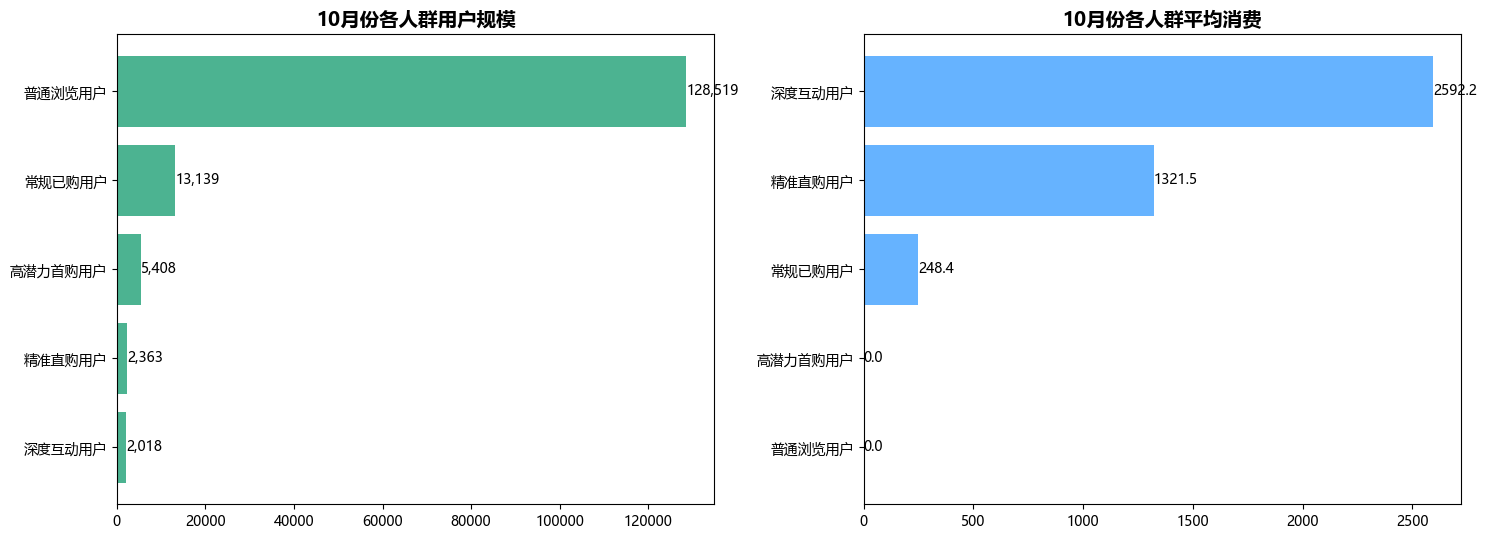

In [9]:
# ============================================================
# 各人群规模与平均消费概览（两张横向条形图并排）
# ============================================================

# 统计每个分层的用户人数（按人数从多到少排序）
seg_counts = final_df['User_Segment'].value_counts()

# 准备一张 1 行 2 列的画布：左图看规模，右图看平均消费
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# ── 左图：各人群用户规模 ──
# 画横向条形图（翻转顺序让最大的在上面），绿色系
axes[0].barh(seg_counts.index[::-1], seg_counts.values[::-1], color='#4CB391')
axes[0].set_title('10月份各人群用户规模', fontsize=14, fontweight='bold')
# 在每个条形右端标出具体人数（千分位）
for i, v in enumerate(seg_counts.values[::-1]):
    axes[0].text(v + 30, i, f'{v:,}', va='center', fontsize=10)

# ── 右图：各人群平均消费 ──
# 按平均消费升序排序后画横向条形图，蓝色系
avg_spend = final_df.groupby('User_Segment')['Total_Spending'].mean().sort_values()
axes[1].barh(avg_spend.index, avg_spend.values, color='#66b3ff')
axes[1].set_title('10月份各人群平均消费', fontsize=14, fontweight='bold')
# 在每个条形右端标出平均消费（1 位小数）
for i, v in enumerate(avg_spend.values):
    axes[1].text(v + 1, i, f'{v:.1f}', va='center', fontsize=10)

# 统一布局后展示整张图
plt.tight_layout()
plt.show()


## 10月份分层结构透视


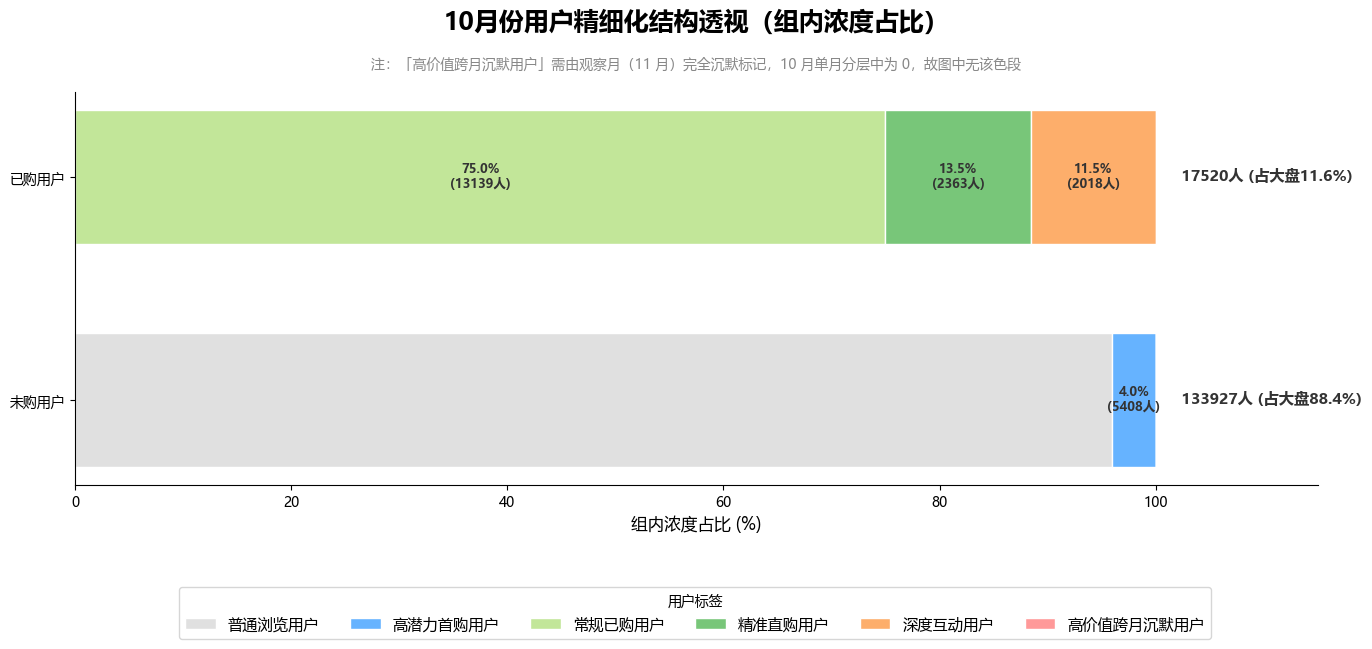

In [10]:
def plot_strategic_segments_matrix_100pct(df):
    """
    绘制 100% 组内归一化横向堆叠条形图，透视用户精细化结构。

    横轴统一为"组内浓度占比"，聚焦展示各战略人群在已购/未购两大基础
    分层内部的真实分布占比，消除底层庞大常规用户群绝对数量造成的
    "视觉坍塌"。

    Parameters:
    -----------
    df : pandas.DataFrame
        包含最终分层结果 'Base_Segment' 和 'User_Segment' 的数据框。

    Returns:
    --------
    None
        直接在前端输出图表。
    """

    # 1. 标签归纳映射
    # 把细分的 User_Segment 标签归纳成适合展示的六大类（取值统一用全称，
    # 与其它图表、正文里的标签名保持一致）
    def categorize_for_plot(label):
        """把一个用户的精细化标签归并到用于绘图的六大类之一。"""
        # 跨月沉默：需观察月沉默行为才能标记，10 月单月分层下不会出现
        if '跨月沉默' in label:
            return '高价值跨月沉默用户'
        elif '深度互动' in label:
            return '深度互动用户'
        elif '直购' in label:
            return '精准直购用户'
        elif '常规' in label:
            return '常规已购用户'
        elif '高潜力' in label:
            return '高潜力首购用户'
        else:
            return '普通浏览用户'

    # 标签来源：若传入表已被 silent_buyer 标记过，就用展示用的 Final_Segment（每位用户一个互斥标签），
    # 否则退回基期 User_Segment（该口径下不会出现“高价值跨月沉默用户”这一类）
    label_col = 'Final_Segment' if 'Final_Segment' in df.columns else 'User_Segment'
    # 新增一列 Plot_Category：对每个用户做标签归并（会就地修改传入的 df）
    df['Plot_Category'] = df[label_col].apply(categorize_for_plot)

    # 2. 交叉表：基础分层（行） × 精细化人群（列），格子值为人数
    plot_data = pd.crosstab(df['Base_Segment'], df['Plot_Category'])

    # 规定图例列的展示顺序（普通浏览 → 高潜力首购 → … → 高价值跨月沉默用户）
    plot_cols = ['普通浏览用户', '高潜力首购用户', '常规已购用户',
                 '精准直购用户', '深度互动用户', '高价值跨月沉默用户']
    # 若某个人群在数据里完全不存在，则补一列全 0，保证列顺序与图例一致
    # （10 月口径下「高价值跨月沉默用户」就是这种情形：它要等观察月沉默标记，见本节下方的图中注释）
    for col in plot_cols:
        if col not in plot_data.columns:
            plot_data[col] = 0
    # 按预定的列顺序重排
    plot_data = plot_data[plot_cols]

    # 规定基础分层行的固定顺序（上：未购，下：已购）
    base_order = ['未购用户', '已购用户']
    # 按该顺序重排行；缺失的行补 0
    plot_data = plot_data.reindex(base_order).fillna(0)
    # 大盘总人数：用于计算"占大盘比例"
    total_users = len(df)

    # 3. 提前算出每一层（每一行）的总人数，后续用于归一化成百分比
    row_totals = plot_data.sum(axis=1)

    # 新建一张宽画布，用于画横向堆叠条形图
    # 画布加高一点：底部要留出放图例的空间（下面 rect 会从 16% 处开始排坐标区）
    fig, ax = plt.subplots(figsize=(14, 6.6))

    # 六大人群各自固定的配色
    colors = {
        '普通浏览用户': '#e0e0e0',
        '高潜力首购用户': '#66b3ff',
        '常规已购用户': '#c2e699',
        '精准直购用户': '#78c679',
        '深度互动用户': '#fdae6b',
        '高价值跨月沉默用户': '#ff9999'
    }

    # 每根条的左侧起始位置：按百分比从 0.0 开始逐段累加
    left_pos = pd.Series([0.0] * len(plot_data), index=plot_data.index)

    # 按预定顺序逐个人群叠画堆叠段
    for category in plot_cols:
        values = plot_data[category]             # 该人群在每层里的绝对人数
        pct_values = (values / row_totals) * 100  # 归一化：该层组内占比（0-100）

        # 在当前累加位置之上叠画这一段（白边分隔各段）
        ax.barh(plot_data.index, pct_values, left=left_pos,
                label=category, color=colors[category], edgecolor='white', height=0.6)

        # 灰色"普通浏览用户"段不写字，其余段内部标注占比与人数
        if category != '普通浏览用户':
            for i, val in enumerate(values):
                if val > 0:
                    pct = pct_values.iloc[i]                   # 该段占比
                    x_pos = left_pos.iloc[i] + pct / 2          # 文字放段中央
                    if pct > 1.5:                               # 段太窄就不写字，避免重叠
                        ax.text(x_pos, i, f'{pct:.1f}%\n({int(val)}人)',
                                ha='center', va='center', color='#333333', fontsize=9, fontweight='bold')

        # 把当前段的占比累加进起始位置，作为下一段的左侧起点
        left_pos += pct_values

    # 4. 最右侧：该层总人数与占大盘比例（固定在 x=102 的文字列）
    for i, (idx, row) in enumerate(plot_data.iterrows()):
        total_bar = row.sum()                              # 该层总人数
        pct_total = (total_bar / total_users) * 100         # 该层占大盘比例
        ax.text(102, i, f' {int(total_bar)}人 (占大盘{pct_total:.1f}%)',
                ha='left', va='center', color='#333333', fontsize=11, fontweight='bold')

    # 5. 装饰：坐标范围 / 标题 / 图例 / 边框
    ax.set_xlim(0, 115)
    # 标题带「10月份」前缀：本图用的是 10 月单月分层表；
    # pad 加大到 45，给下面那行「第 6 类为何为 0」的注释留出空间
    plt.title('10月份用户精细化结构透视（组内浓度占比）', fontsize=18, pad=45, fontweight='bold')
    # 说明第 6 类「高价值跨月沉默用户」为何是 0：它需要观察月（11 月）的完全沉默行为才能标记，
    # 而 10 月单月分层时 silent_buyer 还没被调用 → 该人群尚未生成
    ax.text(0.5, 1.05,
            '注：「高价值跨月沉默用户」需由观察月（11 月）完全沉默标记，10 月单月分层中为 0，故图中无该色段',
            transform=ax.transAxes, ha='center', va='bottom', fontsize=10, color='#888888')
    plt.xlabel('组内浓度占比 (%)', fontsize=12)
    plt.ylabel('', fontsize=12)
    # 图例改挂到整张画布的最底部（fig.legend，单位是画布坐标）。
    # 原来的 plt.legend(bbox_to_anchor=(0.5, -0.08)) 是把图例挂在坐标区外面，
    # tight_layout 不会为它留空间 → 图例框会压住 xlabel「组内浓度占比 (%)」；
    # 现在改用 rect 在画布底部显式留出 16% 的空间放图例，两者不再重叠。
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, title='用户标签', loc='lower center',
               bbox_to_anchor=(0.5, 0.012), ncol=6, fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout(rect=(0, 0.16, 1, 1))
    plt.show()

# 调用 100% 堆叠图函数：透视最终分层表的结构
plot_strategic_segments_matrix_100pct(final_df)


## 各人群 11 月转化率对比


In [11]:
# ═══════════════════════════════════════════════════
# 各人群 11 月转化率对比（购买力/价值）
# ═══════════════════════════════════════════════════
from src.config import PANEL_FILE
from src.analysis import silent_buyer, load_panel

# 已购人群“跨月沉默” = 高价值跨月沉默用户：10月高价值买家在 11 月无任何行为
# ⚠️ 口径说明：先保存 10 月基期标签（Base_User_Segment），再用 silent_buyer 标记跨月沉默；
#    silent_buyer 只新增 High_Value_Silent_Flag / Final_Segment，不改写 User_Segment。
# 六组转化率一律按【事前基期口径】计算（分母 = 10 月全量该标签用户；高价值跨月沉默为 flag 后标签）（分母 = 10 月全量该标签用户）。
# 若改用“11 月仍活跃”的高价值用户（High_Value_Silent_Flag == False）来选 VIP，
# 转化率变成已知未来的条件概率（存活偏差/未来信息泄漏）。

# 复制一份分层表，避免后续新增列影响别处的 final_df
final_df = final_df.copy()
# 先把 10 月基期标签存到独立列，供"事前口径"计算使用
final_df['Base_User_Segment'] = final_df['User_Segment']
# 11 月事件：本单元要统计各人群的 11 月转化率，需要 11 月的行为与购买记录；
# 这里按需读取 11 月（只读这一个月、只取需要的列），
# 不依赖后面「分层结果缓存」单元的 panel_all（本节现在排在它前面）
NOV_COLUMNS = ['event_time', 'event_type', 'price', 'product_id',
               'user_id', 'user_session', 'month']
nov_events = load_panel(PANEL_FILE, months=['2019-11'], columns=NOV_COLUMNS)
# 11 月有任意事件（浏览/加购/购买）的用户 → 用于判定"跨月完全沉默"
nov_tbl_active_ids = set(nov_events['user_id'])

# 调用沉默分流：用 11 月行为把"高价值但 11 月完全沉默"的用户标记出来
# ⚠️ 第二个参数必须是"观察月活跃 user_id 的可迭代集合"，不能直接传 DataFrame：
#    函数内部是 set(active_user_ids)，传 DataFrame 会得到列名，导致所有高价值用户都被判为沉默
final_df = silent_buyer(final_df, nov_tbl_active_ids)

# 逐个提取六组人群的 user_id 数组（基期口径 / 沉默后口径）
# 目标组一：高潜力首购用户（未购人群中按基期标签选取）
mask_potential = final_df['Base_User_Segment'] == '高潜力首购用户'
target_potential_ids = final_df.loc[mask_potential, 'user_id'].to_numpy()
# 对照组：普通浏览用户（基期标签）
mask_control_low = final_df['Base_User_Segment'] == '普通浏览用户'
control_low_value_ids = final_df.loc[mask_control_low, 'user_id'].to_numpy()
# 常规已购用户（基期标签）
mask_regular = final_df['Base_User_Segment'] == '常规已购用户'
target_regular_ids = final_df.loc[mask_regular, 'user_id'].to_numpy()
# 精准直购用户（基期标签）
mask_efficient_vip = final_df['Base_User_Segment'] == '精准直购用户'
target_efficient_vip_ids = final_df.loc[mask_efficient_vip, 'user_id'].to_numpy()
# 深度互动用户（基期标签）
mask_immersive_vip = final_df['Base_User_Segment'] == '深度互动用户'
target_immersive_vip_ids = final_df.loc[mask_immersive_vip, 'user_id'].to_numpy()
# 高价值跨月沉默用户：按 silent_buyer 给出的跨月沉默标记取（User_Segment 不再被改写）
mask_silent = final_df['High_Value_Silent_Flag']
target_silent_ids = final_df.loc[mask_silent, 'user_id'].to_numpy()


def evaluate_nov_performance(user_list, group_name):
    """评估某一人群在 11 月的转化表现；人数为 0 时返回 None 表示跳过。"""
    if len(user_list) == 0:
        return None
    # 取该人群在 11 月的行为记录
    group_nov = nov_events[nov_events['user_id'].isin(user_list)]
    # 只保留 11 月的购买事件
    nov_purchases = group_nov[group_nov['event_type'] == 'purchase']
    # 下单人数（按 user_id 去重）
    buyers = nov_purchases['user_id'].nunique()
    # 转化率 = 下单人数 / 该人群总人数
    cvr = buyers / len(user_list)
    # 11 月营收 = 购买事件价格之和
    rev = nov_purchases['price'].sum()
    # 人均消费 = 营收 / 下单人数（没人下单时为 0，避免除零）
    arppu = rev / buyers if buyers > 0 else 0
    return {
        '人群分组': group_name,
        '人数': len(user_list),
        '11月下单': buyers,
        '转化率': f"{cvr:.2%}",
        '11月营收': round(rev, 2),
        '人均消费': round(arppu, 2)
    }


# 六组待评估人群：(user_id 数组, 展示名)
groups = [
    (target_potential_ids, "高潜力首购用户"),
    (control_low_value_ids, "普通浏览用户"),
    (target_regular_ids, "常规已购用户"),
    (target_efficient_vip_ids, "精准直购用户"),
    (target_immersive_vip_ids, "深度互动用户"),
    (target_silent_ids, "高价值跨月沉默用户（11月完全沉默，转化率应为0%）"),
]

# 逐组评估，跳过没有样本的分组，把有效行汇总成报告表
report_rows = []
for ids, name in groups:
    row = evaluate_nov_performance(ids, name)
    if row is not None:
        report_rows.append(row)
report = pd.DataFrame(report_rows)
# 以 HTML 表格展示最终转化率报告
display(HTML(report.to_html(index=False)))


人群分组,人数,11月下单,转化率,11月营收,人均消费
高潜力首购用户,5408,719,13.30%,399843.12,556.11
普通浏览用户,128519,6959,5.41%,3257092.60,468.04
常规已购用户,13139,2854,21.72%,1529278.19,535.84
精准直购用户,2363,865,36.61%,1179416.07,1363.49
深度互动用户,2018,927,45.94%,1567187.28,1690.60
高价值跨月沉默用户（11月完全沉默，转化率应为0%）,1384,0,0.00%,0.00,0.00


## 分层结果缓存

In [12]:

from src.analysis import build_month_tables, load_panel
from src.config import MONTHS, MONTH_CACHE_DIR, PANEL_FILE

# 分析只需这 7 列（category_code / brand 等字符串列不读，省 IO 与内存）
PANEL_COLUMNS = ['event_time', 'event_type', 'price', 'product_id', 'user_id', 'user_session', 'month']

# 7 个月面板：后续章节共用同一份，避免重复加载
panel_all = load_panel(PANEL_FILE, months=MONTHS, columns=PANEL_COLUMNS)

# 缓存目录：一个月一个文件 month_YYYY-MM.parquet（可随时删除重建）
CACHE_DIR = MONTH_CACHE_DIR   # 路径集中在 src/config.py：<项目根>/data/_month_cache

# 面板 → 月度表：month_tables['2019-11'] = 该月特征 + 该月标签（当月独立分层）
# 有缓存文件就直接读，没有才现算并落盘（首次运行约 40 秒/月）
month_tables = build_month_tables(panel_all, MONTHS, cache_dir=CACHE_DIR)
print('月度表就绪:', ', '.join(MONTHS))


  2019-10: 月度表（缓存）
  2019-11: 月度表（缓存）
  2019-12: 月度表（缓存）
  2020-01: 月度表（缓存）
  2020-02: 月度表（缓存）
  2020-03: 月度表（缓存）
  2020-04: 月度表（缓存）
月度表就绪: 2019-10, 2019-11, 2019-12, 2020-01, 2020-02, 2020-03, 2020-04


# 模型验证

## 时间外验证：7 个月数据逐对检验

### 实验设计

在 7 个月面板上逐对运行时间外验证（基期月建模 → 未来月验证），用未来月份的数据检验标签的判别力（购买概率排序的有效性验证见后文「基于购买概率的用户排序」）：

- **实验一（未购人群）**：使用某个月（如 10 月）的用户行为进行分层，再观察这些用户在下一个月（11 月）是否发生购买。连续进行 6 组验证，检验高潜力用户是否更容易在次月购买。
- **实验二（已购人群·跨月沉默）**：先识别某个月（如 10 月）的高价值用户，再观察他们在下一个月（11 月）是否完全没有浏览、加购或购买行为。将完全沉默的用户标记为“高价值跨月沉默用户”，然后观察他们在再下一个月（12 月）的购买情况。连续进行 5 组验证，检验跨月沉默能否预示后续购买活跃度下降。

实验结果解读：
- **实验一**：比较“高潜力首购用户”和“普通浏览用户”的次月购买率。如果前者持续高于后者，且购买率差异具有实际意义，就说明这套分层方法可能有助于识别更有转化潜力的用户。连续 6 组结果都呈现相同趋势，可以进一步增强结论的可信度。
- **实验二**：比较“高价值跨月沉默用户”和“观察月仍有活动的高价值用户”在再下一个月的购买率。如果前者持续低于后者，说明跨月完全沉默可能是后续购买活跃度下降的有效预警信号。连续 5 组结果都呈现相同趋势，可以进一步支持这一判断，但仍需结合购买率差异、样本量及统计不确定性进行评估。

实验一：未购人群


训练月,验证月,目标人数,目标购买率,对照人数,对照购买率,p值
2019-10,2019-11,5408,13.3%,128519,5.4%,2.2e-131
2019-11,2019-12,17612,14.0%,144891,4.7%,0.0e+00
2019-12,2020-01,21243,6.8%,182764,2.3%,0.0e+00
2020-01,2020-02,19182,9.6%,182626,2.8%,0.0e+00
2020-02,2020-03,19893,11.2%,171732,3.4%,0.0e+00
2020-03,2020-04,17555,9.0%,165265,3.6%,4.5e-262


实验二：已购人群的跨月沉默


训练月,沉默月,验证月,目标人数,目标购买率,对照人数,对照购买率,p值
2019-10,2019-11,2019-12,1384,6.9%,2997,38.6%,5.9e-103
2019-11,2019-12,2020-01,1824,6.7%,3813,33.4%,3.1e-104
2019-12,2020-01,2020-02,2042,7.9%,4280,35.4%,1.1e-118
2020-01,2020-02,2020-03,1591,9.6%,2922,41.4%,6.4e-109
2020-02,2020-03,2020-04,1848,5.9%,3112,25.8%,4.2e-68


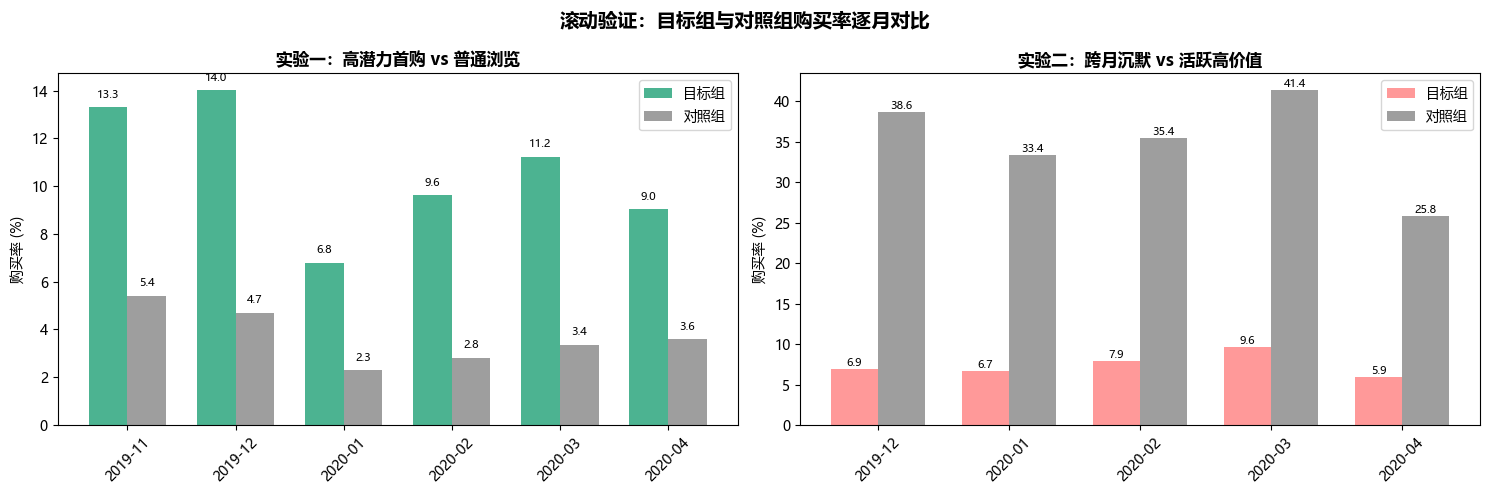

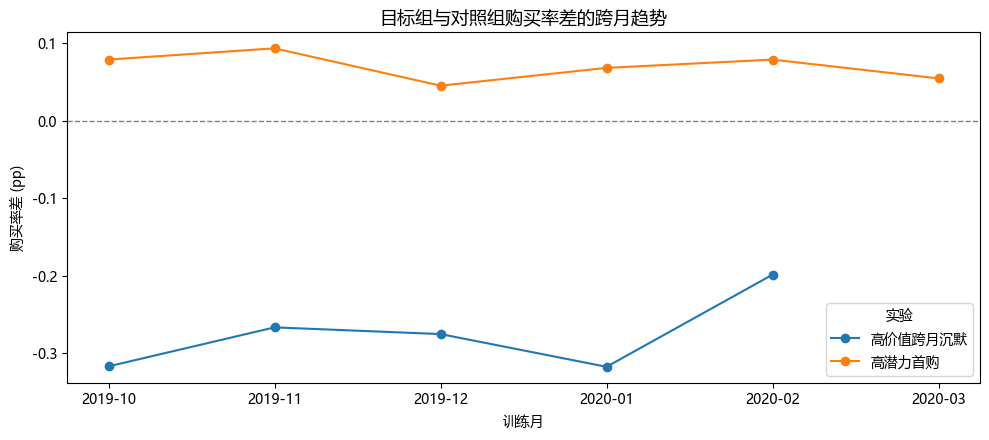

In [13]:
# 滚动时间外验证：读取结果或重新计算

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, HTML
from src.config import MONTHS, OUTPUT_ROLLING


# True：重新计算；False：读取已有 CSV
RECOMPUTE = False

if RECOMPUTE:
    from src.analysis import rolling_validation

    res = rolling_validation(month_tables, MONTHS)
    rates = res['验证表']
    rates.to_csv(OUTPUT_ROLLING, index=False, encoding='utf-8-sig')
else:
    if not Path(OUTPUT_ROLLING).exists():
        raise SystemExit(
            '未找到滚动验证结果 CSV（rolling_validation_results.csv）。\n'
            '请先运行 `python -m src.run_rolling`（需 data/panel_7months.parquet），'
            '或将上方 RECOMPUTE 改为 True 在本 Notebook 内重算。'
        )

    rates = pd.read_csv(OUTPUT_ROLLING)


# 格式化函数

def fmt_pct(x):
    """将小数格式化为百分数。"""
    if pd.isna(x):
        return '—'
    return f'{x:.1%}'


def fmt_p(x):
    """将 p 值格式化为科学计数法。"""
    if pd.isna(x):
        return '—'
    return f'{x:.1e}'


def fmt_rates(df, keep_cols):
    """格式化购买率和 p 值，并保留指定列。"""
    out = df.copy()
    out['目标购买率'] = out['目标购买率'].map(fmt_pct)
    out['对照购买率'] = out['对照购买率'].map(fmt_pct)
    out['p值'] = out['p值'].map(fmt_p)
    return out[keep_cols]


# 拆分实验结果

rates1 = rates[
    rates['实验'].str.contains('高潜力首购', na=False)
].copy()

rates2 = rates[
    rates['实验'].str.contains('沉默', na=False)
].copy()


# 实验一：未购人群

print('实验一：未购人群')

display(HTML(
    fmt_rates(
        rates1,
        [
            '训练月',
            '验证月',
            '目标人数',
            '目标购买率',
            '对照人数',
            '对照购买率',
            'p值'
        ]
    ).to_html(index=False)
))


# 实验二：已购人群的跨月沉默

print('实验二：已购人群的跨月沉默')

display(HTML(
    fmt_rates(
        rates2,
        [
            '训练月',
            '沉默月',
            '验证月',
            '目标人数',
            '目标购买率',
            '对照人数',
            '对照购买率',
            'p值'
        ]
    ).to_html(index=False)
))


# 购买率对比柱状图

exp1 = rates[
    rates['实验'].str.contains('高潜力首购', na=False)
]

exp2 = rates[
    rates['实验'].str.contains('沉默', na=False)
]


def _plot_target_vs_control(
    ax,
    group_df,
    title_text,
    color_target,
    color_control
):
    """绘制目标组与对照组的逐月购买率对比。"""
    x = np.arange(len(group_df))
    w = 0.36

    target_rates = group_df['目标购买率'] * 100
    control_rates = group_df['对照购买率'] * 100

    ax.bar(
        x - w / 2,
        target_rates,
        w,
        label='目标组',
        color=color_target
    )

    ax.bar(
        x + w / 2,
        control_rates,
        w,
        label='对照组',
        color=color_control
    )

    for xi, (t, c) in enumerate(
        zip(target_rates, control_rates)
    ):
        ax.text(
            xi - w / 2,
            t + 0.4,
            f'{t:.1f}',
            ha='center',
            fontsize=8
        )
        ax.text(
            xi + w / 2,
            c + 0.4,
            f'{c:.1f}',
            ha='center',
            fontsize=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels(group_df['验证月'], rotation=45)
    ax.set_ylabel('购买率 (%)')
    ax.set_title(title_text, fontsize=12, fontweight='bold')
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

_plot_target_vs_control(
    axes[0],
    exp1,
    '实验一：高潜力首购 vs 普通浏览',
    '#4CB391',
    '#9e9e9e'
)

_plot_target_vs_control(
    axes[1],
    exp2,
    '实验二：跨月沉默 vs 活跃高价值',
    '#ff9999',
    '#9e9e9e'
)

plt.suptitle(
    '滚动验证：目标组与对照组购买率逐月对比',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# 购买率差的跨月趋势

piv = (
    rates
    .pivot(
        index='训练月',
        columns='实验',
        values='购买率差'
    )
    .sort_index()
)

ax = piv.plot(marker='o', figsize=(10, 4.5))

ax.axhline(0, color='gray', ls='--', lw=1)
ax.set_ylabel('购买率差 (pp)')
ax.set_title(
    '目标组与对照组购买率差的跨月趋势',
    fontsize=13
)

plt.tight_layout()
plt.show()

### 实验结果报告

通过结果表和图表，比较两组用户在未来月份的购买表现，并观察这种差异是否随时间保持稳定，得出的结论如下：

- **实验一：** 高潜力首购用户的次月购买率应高于普通浏览用户，购买率差预期为正。
- **实验二：** 高价值跨月沉默用户在再下一个月的购买率应低于观察月仍有活动的高价值用户，购买率差预期为负。

判断结果时，需要综合考虑购买率差异、样本量和 p 值。连续多个时间窗口呈现相同方向的差异，可以增强结论的可信度，但不能仅凭方向一致或统计显著，就认定标签一定具有实际业务价值。

需要注意：实验一中的“未购用户”指基期当月没有购买行为的用户，不一定是历史从未购买过的新客；实验二中的“跨月沉默”则是流失风险信号，并不代表用户已经确定流失。

## 基于购买概率的用户排序

完成用户分层后，接下来需要解决一个实际的营销问题：当营销预算和触达名额有限时，每类用户中应该优先联系谁？

本节根据模型预测的购买概率，在各个人群内部对用户从高到低进行排序，并依次选取排名靠前的用户，形成优先触达名单。同时，通过比较不同选取范围内的实际购买表现，评估这种排序能否帮助我们更有效地筛选目标用户。

这里的购买概率反映的是用户本身的购买可能性，并不等于营销触达能够带来的额外转化效果。分析的目的是帮助有限的营销资源优先覆盖更值得关注的用户，而不是直接证明触达这些用户一定能带来增量收益。

In [14]:
# 打分：调用纯工具 LR_predict_rank（预测『预测月』的购买概率 + 在传入用户内部排名）
# ⚠️ 时间窗口（由工具函数内部保证无泄漏）：
#    - 训练：更早月份的「训练行为月 → 训练结果月」样本（该月全体用户），一个 LR 模型；
#    - 打分：只对传入的用户名单打分，名次只在这些用户内部计算（1 ~ N）；
#    - 因此 10 月是最早的建模月、没有更早的训练行为月，无法打分，打分最早从 11 月开始。
import numpy as np
from src.analysis import LR_predict_rank
from src.config import POOL_TOP_RATIO

# 本轮训练结果月
SCORE_MONTH = '2019-11'

# ── 第一步：取该月的月度表（特征 + 该月标签，已由"月度表缓存"cell 算好）──
# 变量名用 nov_df：这张表是 11 月特征 + 11 月标签，
# 不要和前面「用户价值分层」章节那份 10 月分层表 final_df 混用（同名极易误读）
nov_df = month_tables[SCORE_MONTH].copy()

# 打分结果列先占位：本次只对"高潜力首购用户"打分，其余标签留 NaN
nov_df['First_Purchase_Prob'] = np.nan
nov_df['First_Purchase_Rank'] = np.nan
# 已购两列也先占位：导出名单的函数要求这些列存在；后续要对已购用户打分时在这里补齐
nov_df['Repurchase_Prob'] = np.nan
nov_df['Repurchase_Rank'] = np.nan

# ── 第二步：对"高潜力首购用户"调用工具函数──
# 后续要给别的标签打分时，照着下面两行再写一次即可（工具函数本身与人群无关）
target_ids = nov_df.loc[nov_df['User_Segment'] == '高潜力首购用户', 'user_id'].to_numpy()
# 传入 7 张月度表：函数内部用更早月份的历史样本训练，再对本轮名单打分
ranked = LR_predict_rank(month_tables, SCORE_MONTH, target_ids)
# 按 user_id 把概率与名次映射回名单
nov_df['First_Purchase_Prob'] = nov_df['user_id'].map(ranked.set_index('user_id')['Prob'])
nov_df['First_Purchase_Rank'] = nov_df['user_id'].map(ranked.set_index('user_id')['Rank'])
print(f'已打分：高潜力首购用户 {len(target_ids):,} 人（名次 1 ~ {len(target_ids):,}）')

# ── 第三步：调用方口径的"优先触达"标记（名单内前 POOL_TOP_RATIO）──
in_list = nov_df['First_Purchase_Rank'].notna()
k = int(np.ceil(int(in_list.sum()) * POOL_TOP_RATIO))
nov_df['TopK_Flag'] = np.nan
nov_df.loc[in_list, 'TopK_Flag'] = (nov_df.loc[in_list, 'First_Purchase_Rank'] <= k).astype(int)
print(f"历史窗口训练（无泄漏）：候选名单（{SCORE_MONTH} 高潜力首购）{int(in_list.sum()):,} 人 → "
      f"TopK_Flag 标记名单内前 {POOL_TOP_RATIO:.0%}（{int((nov_df['TopK_Flag'] == 1).sum()):,} 人）优先触达")

# ── 预览：按首购名次取前 10 ──
top_preview = (nov_df.loc[nov_df['User_Segment'] == '高潜力首购用户',
                            ['user_id', 'Activity', 'Friction',
                             'First_Purchase_Prob', 'First_Purchase_Rank', 'TopK_Flag']]
               .sort_values('First_Purchase_Rank').head(10))
display(HTML(top_preview.to_html(index=False)))

# ── 名单规模核对 ──
print('TopK_Flag=1 的人数:', int(nov_df['TopK_Flag'].sum()))


已打分：高潜力首购用户 17,612 人（名次 1 ~ 17,612）
历史窗口训练（无泄漏）：候选名单（2019-11 高潜力首购）17,612 人 → TopK_Flag 标记名单内前 50%（8,806 人）优先触达


user_id,Activity,Friction,First_Purchase_Prob,First_Purchase_Rank,TopK_Flag
568778435,7.319523,3,0.749083,1.0,1.0
568826117,4.697618,13,0.495025,2.0,1.0
516308435,4.190522,3,0.393192,3.0,1.0
551679343,3.862066,1,0.380722,4.0,1.0
568777364,3.862815,1,0.360171,5.0,1.0
513778820,4.076560,2,0.350137,6.0,1.0
564442389,3.776180,5,0.342590,7.0,1.0
515188887,3.655779,4,0.322126,8.0,1.0
535717297,3.548007,3,0.318400,9.0,1.0
513674548,3.665256,3,0.315864,10.0,1.0


TopK_Flag=1 的人数: 8806


### 购买概率排序的有效性验证

工具函数 LR_predict_rank 只负责为用户预测购买概率并生成排名，排名靠前并不意味着这些用户一定更容易购买。因此，还需要结合后续月份的真实购买记录，检验模型的排序是否有效：**模型排在前面的用户，实际购买率是否更高？**

本节将这一验证扩展到多轮时间外预测。每轮使用历史数据训练模型，根据当轮打分月份（2019 年 11 月至 2020 年 3 月）的用户特征计算购买概率，再用下一预测月的实际购买结果检验排序效果。2019 年 10 月是最早的建模月份，没有更早的训练数据可用于生成有效的时间外排名，因此不纳入打分验证。

每轮主要进行两项检验：

- 按购买概率排序取前 50% 的效果： 在“高潜力首购用户”名单内部，按购买概率从高到低排序，比较排名前 50% 的用户、完整名单以及全体当月未购用户基线的预测月购买率。通过这三组对比，判断优先选择排名靠前的用户，是否比覆盖整份名单或随机面向全部未购用户更有效。

- 排名分桶与单调性： 根据预测排名将名单划分为 4 个梯度，分别计算各桶在预测月的实际购买率。如果排名越靠前，实际购买率整体越高，说明模型能够较好地区分不同购买潜力的用户，排序结果更有助于确定触达优先级。


训练结果月,预测月,名单人数,基线(全体未购),全体名单,LR Top-k,Top-k人数,Top-k提升(pp)
2019-11,2019-12,17612,5.70%,14.02%,17.27%,8806,+3.25
2019-12,2020-01,21243,2.76%,6.80%,8.26%,10622,+1.46
2020-01,2020-02,19182,3.46%,9.62%,12.19%,9591,+2.57
2020-02,2020-03,19893,4.18%,11.24%,14.40%,9947,+3.16
2020-03,2020-04,17555,4.11%,9.03%,11.83%,8778,+2.79


高潜力首购名单——名次分桶的预测月购买率（越靠前越高 = 排序有效）：
  2019-11→2019-12: 前10% 22.02% | 10-25% 17.38% | 25-50% 15.31% | 后50% 10.78%
  2019-12→2020-01: 前10% 10.73% | 10-25% 8.69% | 25-50% 7.00% | 后50% 5.34%
  2020-01→2020-02: 前10% 18.39% | 10-25% 13.07% | 25-50% 9.18% | 后50% 7.05%
  2020-02→2020-03: 前10% 20.40% | 10-25% 14.95% | 25-50% 11.66% | 后50% 8.08%
  2020-03→2020-04: 前10% 15.21% | 10-25% 11.70% | 25-50% 10.55% | 后50% 6.24%


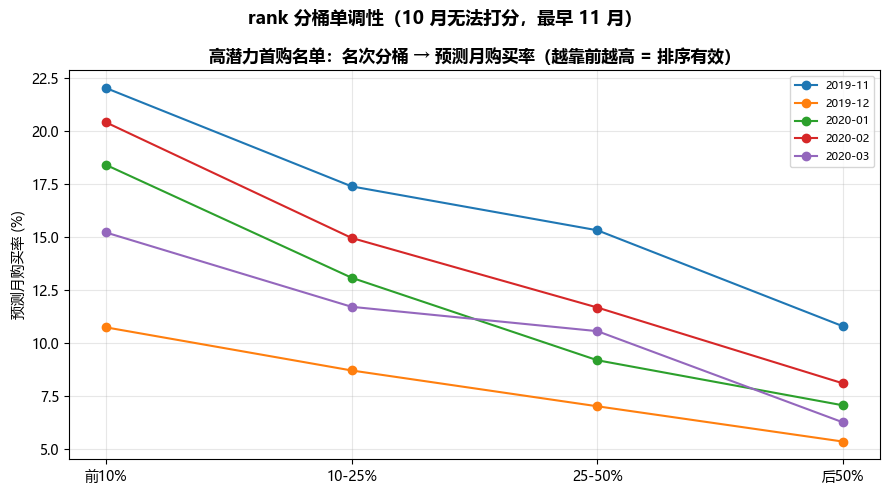

In [15]:
# ═══════════════════════════════════════════════════
# 排序有效性验证：LR_predict_rank 给出的名次是否有效
# （高潜力首购名单视角，覆盖每一轮打分）
# 说明：复用前面“月度表缓存”Cell 已准备好的 7 张月度表。
# ═══════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, HTML

from src.analysis import _next_month, LR_predict_rank
from src.config import MONTHS, POOL_TOP_RATIO


# 月度表：来自前面的“月度表缓存”Cell
# 每月一张，包含该月特征和用户标签


# ── 确定可打分月份 ──
# 2019-10 是最早的建模月，无法进行时间外打分；
# 训练结果月的下一个月必须存在于面板中，才能验证购买结果。

score_months = []

for m in MONTHS:
    if m > '2019-10' and _next_month(m) in MONTHS:
        score_months.append(m)


# ── 名次分桶：按人数比例划分四个区间 ──

BUCKETS = [
    (0.0, 0.10, '前10%'),
    (0.10, 0.25, '10-25%'),
    (0.25, 0.50, '25-50%'),
    (0.50, 1.0, '后50%')
]


def bucket_rates(rank_sorted_df, y_col):
    """
    按 Rank 升序排序后，按人数比例划分四个区间，
    返回各区间的实际购买率。
    """
    n = len(rank_sorted_df)

    if n == 0:
        return [np.nan] * len(BUCKETS)

    rates, start = [], 0

    for lo, hi, _ in BUCKETS:
        end = int(np.ceil(hi * n))
        rates.append(
            rank_sorted_df.iloc[start:end][y_col].mean()
        )
        start = end

    return rates


# ── 逐轮打分：验证高潜力首购用户名单 ──

list_rows = []
list_buckets = {}

for sm in score_months:

    # 预测月 = 训练结果月的下一个月
    nm = _next_month(sm)

    # 预测月的实际购买用户，仅用于验证，不参与本轮打分
    table_nm = month_tables[nm]

    buyers_nm = set(
        table_nm.loc[
            table_nm['Purchase_Frequency'] > 0,
            'user_id'
        ]
    )

    # 训练结果月的月度表
    seg_sc = month_tables[sm].copy()

    # 根据预测月真实购买记录生成验证标签
    seg_sc['bought'] = (
        seg_sc['user_id']
        .isin(buyers_nm)
        .astype(int)
    )

    # 打分名单：当月被标记为“高潜力首购用户”的用户
    target_ids = seg_sc.loc[
        seg_sc['User_Segment'].eq('高潜力首购用户'),
        'user_id'
    ].to_numpy()

    # 使用模型计算购买概率和名单内排名
    scored = LR_predict_rank(
        month_tables,
        sm,
        target_ids
    )

    # 合并预测月真实购买结果
    scored = scored.merge(
        seg_sc[['user_id', 'bought']],
        on='user_id',
        how='left'
    )

    # 名单内 Top-k
    k = int(np.ceil(len(scored) * POOL_TOP_RATIO))

    top = scored[scored['Rank'] <= k]

    # 基线：训练结果月的全体未购用户，在预测月的购买率
    baseline = seg_sc.loc[
        seg_sc['Purchase_Frequency'].eq(0),
        'bought'
    ].mean()

    # 本轮结果：名单人数 / 基线 / 全体名单 / LR Top-k
    list_rows.append({
        '训练结果月': sm,
        '预测月': nm,
        '名单人数': len(scored),
        '基线(全体未购)': baseline,
        '全体名单': scored['bought'].mean(),
        'LR Top-k': top['bought'].mean() if len(top) else np.nan,
        'Top-k人数': len(top)
    })

    # 名次分桶的预测月购买率（按 Rank 升序切桶）
    list_buckets[sm] = bucket_rates(
        scored.sort_values('Rank'),
        'bought'
    )



# ── 汇总：逐月结果表 + Top-k 相对全体名单的提升 ──

list_df = pd.DataFrame(list_rows)

list_df['Top-k提升(pp)'] = (
    list_df['LR Top-k'] - list_df['全体名单']
) * 100


def _fmt_pct2(x):
    """把小数格式化为两位百分数；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:.2%}'


def _fmt_pp(x):
    """把差值格式化为带符号的两位小数（百分点）；缺失值显示为 —。"""
    if pd.isna(x):
        return '—'
    return f'{x:+.2f}'


# 展示用的三列购买率与提升列转成易读文本
show = list_df.copy()

for c in ['基线(全体未购)', '全体名单', 'LR Top-k']:
    show[c] = show[c].map(_fmt_pct2)

show['Top-k提升(pp)'] = show['Top-k提升(pp)'].map(_fmt_pp)

display(HTML('<h3>高潜力首购名单：LR Top-k vs 全体名单 vs 基线（逐月时间外验证）</h3>'))
display(HTML(show.to_html(index=False)))


# ── 逐月分桶的预测月购买率 ──

print('高潜力首购名单——名次分桶的预测月购买率（越靠前越高 = 排序有效）：')

for sm, rates_by_bucket in list_buckets.items():
    parts = []
    for bucket, rate in zip(BUCKETS, rates_by_bucket):
        parts.append(f'{bucket[2]} {rate:.2%}')
    print(f'  {sm}→{_next_month(sm)}: ' + ' | '.join(parts))


# ── 分桶单调性图 ──
# 画图意图：若 LR 排序有效，越靠前的 rank 分桶购买率应越高（曲线单调下降）

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(BUCKETS))

for sm, rates_by_bucket in list_buckets.items():
    ax.plot(x, np.array(rates_by_bucket) * 100, marker='o', label=sm)

ax.set_xticks(x)
ax.set_xticklabels([b[2] for b in BUCKETS])
ax.set_ylabel('预测月购买率 (%)')
ax.set_title('高潜力首购名单：名次分桶 → 预测月购买率（越靠前越高 = 排序有效）', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.suptitle('rank 分桶单调性（10 月无法打分，最早 11 月）', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 结果持久化

In [16]:
# ============================================================
# 名单导出：供运营直接使用的 CSV 文件
# ============================================================
import importlib
import src.analysis as _ana

importlib.reload(_ana)
# 导入名单导出函数
from src.analysis import export_tracking
from src.config import OUTPUT_TRACKING

# 候选触达名单：11 月高潜力首购用户（名单内按购买概率排序，TopK_Flag=1 优先触达）
# nov_df 来自上一个单元：month_tables['2019-11'] 的 11 月特征 + 11 月标签
tracking_cand = export_tracking(nov_df, OUTPUT_TRACKING,
                                segments=['高潜力首购用户'])
print(f"已导出候选触达名单 {len(tracking_cand):,} 名用户（11月高潜力首购）至 {OUTPUT_TRACKING}")
# 注：跨月沉默高价值（基期高价值在观察月完全沉默）由 silent_buyer 写入 High_Value_Silent_Flag，
#     需在观察月结束后单独判定（用于下个月召回），不在本次打分名单内——沉默是事后标记，天然滞后一个月。


已导出候选触达名单 17,612 名用户（11月高潜力首购）至 D:\Code\ecommerce-user-behavior-segmentation\results\tracked_users_list_Nov.csv


## 用户标签稳定性与跨月变化

用户分层完成后，还需要回答一个实际问题：**这些标签能够稳定多久？一个用户被划入某类人群后，后续月份会继续保持原标签，还是会逐渐转变为其他类型？**

为此，本节固定 2019-10 作为基期，先对当月用户完成分层，再逐月追踪同一批用户在后续月份的标签变化。7 个月用户面板中采用 5% 抽样，约 78 万条用户月记录。后续月份不重新拟合阈值，而是始终沿用 2019-10 得到的分层切分标准，重新计算用户当月标签。

主要观察两个方面：

- 标签如何变化：统计 10 月各类用户在后续月份分别保持原标签、转变为其他标签或完全没有任何行为（沉默）的比例，从而观察不同人群的主要变化路径。

- 标签能保持多久：计算各类用户随时间推移仍保持原标签的比例。保持率越高，说明该类用户的行为特征越稳定；下降越快，则说明该类用户更容易发生行为变化或转向其他人群。

**为什么要固定 10 月的分层阈值**

跨月比较时必须保证使用的是同一把尺子。如果每个月重新拟合 GMM 或重新计算分位数阈值，切分线本身会随着当月用户分布发生变化。例如，Activity 的阈值可能从 −0.07 漂移到 −1.01。此时用户标签发生变化，既可能是用户自身行为变了，也可能只是评价标准变了。

因此，本节冻结 2019-10 的阈值，只让用户的实际行为随月份变化。这样观察到的标签变化，才能更准确地反映用户自身行为和价值状态的变化，并据此判断各类用户标签的稳定性及其大致**有效期**。


In [17]:
# ═══════════════════════════════════════════════════
# 队列迁移分析（结果默认读取 CSV；如需重算运行 python -m src.run_cohort，约 10-20 分钟）
# ═══════════════════════════════════════════════════
import importlib
import src.config as _cfg
# 防御：kernel 早于本版本启动时，刷新配置缓存
importlib.reload(_cfg)
import src.analysis as _ana
importlib.reload(_ana)
import os
from pathlib import Path
import pandas as pd
import numpy as np
from src.config import OUTPUT_COHORT_LABELS

# 结果文件不存在时报错退出，提示用户先跑 run_cohort.py（防御性检查）
if not Path(OUTPUT_COHORT_LABELS).exists():
    raise SystemExit(
        '未找到 cohort_frozen_labels.csv。请先运行 `python -m src.run_cohort`'
        '（需 7 个月面板，约 10-20 分钟）。')
# 读取冻结标签结果：每个用户在每个月的标签构成
fl = pd.read_csv(OUTPUT_COHORT_LABELS)
# 标签的固定展示顺序（迁移分析中统一使用这个顺序）
LABELS_ORDER = ['普通浏览用户', '高潜力首购用户', '常规已购用户',
                '精准直购用户', '深度互动用户', '高价值跨月沉默用户']


### 用户标签稳定性与运营启示

#### 核心结论：用户标签具有明显的月度动态性

以 2019 年 10 月的用户分组为基准，持续追踪同一批用户后发现，各类标签的跨月保持率普遍偏低，且随着时间推移持续下降。这说明用户的购买和活跃行为会随月份变化，**分层标签更适合反映用户当月的行为状态，而不是用户长期不变的属性**。

| 10 月标签 | 11 月保持率 | 2020 年 1 月保持率 | 2020 年 4 月保持率 |
|---|---:|---:|---:|
| 普通浏览 | 32.3% | 24.6% | 17.1% |
| 高潜力首购 | 16.7% | 7.6% | 5.1% |
| 常规已购 | 16.2% | 8.5% | 6.1% |
| 精准直购 | 10.9% | 5.4% | 1.8% |
| 深度互动 | 18.8% | 7.8% | 2.3% |

次月标签保持率仅为 **10.9%–32.3%**；到 2020 年 4 月，各组保持原标签的比例进一步降至 **1.8%–17.1%**。其中，普通浏览的保持率最高，但这不代表其客户忠诚度最高。该标签主要承接当月未购买、活跃度较低的用户，因此更像是一个常见的状态归类，而不是用户关系稳定的证明。

出现这种变化，与标签的划分方式有关：标签同时取决于用户当月是否购买、购买价值及活跃程度。用户即使长期存在，只要当月行为发生变化，也可能被划分到其他标签；如果当月完全没有行为，则会进入无活动状态。

#### 标签转化去向：不同人群的变化路径并不相同

观察 2019 年 10 月各组用户在 11 月的去向，可以看到，用户不仅会转向其他标签，也可能暂时没有任何活动。其中，普通浏览和高潜力首购人群更容易转向无活动或普通浏览状态；购买用户中，常规已购的无活动比例较高，而深度互动用户的跨月表现相对较好。

| 10 月标签 | 11 月无活动 | 11 月主要去向 | 保持原标签 |
|---|---:|---|---:|
| 普通浏览 | 56.5% | 普通浏览 32.3%；高潜力首购 5.8%；转已购 5.5% | 32.3% |
| 高潜力首购 | 34.0% | 普通浏览 36.0%；常规已购 10.2%；升级高价值 3.1% | 16.7% |
| 常规已购 | 40.5% | 普通浏览 28.5%；高潜力首购 9.2%；升级高价值 5.5% | 16.2% |
| 精准直购 | 38.1% | 普通浏览 19.4%；常规已购 18.7%；深度互动 7.0%；高潜力首购 5.9% | 10.9% |
| 深度互动 | 24.0% | 常规已购 21.6%；普通浏览 20.2%；高潜力首购 9.9%；精准直购 5.6% | 18.8% |

从这些转化路径中，可以看到三个值得关注的现象：

- **普通浏览是常见的回落状态。** 10 月普通浏览用户中，11 月有 32.3% 保持原标签，但也有 56.5% 进入无活动状态。与此同时，5.8% 转为高潜力首购、5.5% 转为已购，说明这一大群体中仍有值得进一步识别和触达的用户。
- **深度互动用户的跨月表现相对较好。** 这组用户在 11 月进入无活动状态的比例为 24.0%，低于常规已购的 40.5% 和精准直购的 38.1%。此外，46.0% 的用户仍落在已购相关标签中，包括保持深度互动、转为常规已购或精准直购。这说明该组用户的购买行为和站内互动在次月仍有较明显的延续。
- **常规已购用户需要重点关注。** 该组有 40.5% 在次月没有任何活动；从后续月份看，到 2020 年 4 月，无活动用户占比约为 70%。这表明，仅凭过去购买过商品，并不能保证用户会持续活跃或再次购买。

#### 对运营的启示

**第一，营销名单需要按月更新。** 用户标签会随购买和活跃行为变化，因此更适合用于当月的目标人群筛选和差异化触达，不宜把某次分层结果长期当作固定的客户属性。

**第二，重点识别普通浏览中的转化机会。** 普通浏览人数可能较多，但其中既有暂时没有购买意愿的用户，也有可能进一步转化的人群。可结合活跃度、加购行为和购买概率，优先筛选更值得触达的用户，而不是对整个群体采用相同的营销方式。

**第三，持续经营深度互动用户。** 这组用户的跨月购买状态延续性相对较好，可以优先考虑会员维护、新品体验或定向内容触达；但仍应持续观察其后续购买表现，避免仅凭当月标签判断长期价值。

**第四，及时唤醒常规已购和沉默的高价值用户。** 常规已购用户次月无活动比例较高，可在其活跃度下降后安排适当的回访或促销触达。对于高价值用户，即使某个月完全没有活动，也不应直接认定为永久流失：后续重新活跃时，用户仍可能回到已购相关标签。此类用户可以作为定向召回的候选对象。

#### 小结

总体而言，用户标签反映的是**用户在某个月的行为与价值状态**，而非永久不变的客户类型。标签稳定性分析的意义，不是要求所有用户长期停留在原有分组，而是识别哪些人群更容易沉默、哪些人群仍有转化机会，以及哪些高价值用户需要及时维护。实际运营中，应根据最新行为定期刷新名单，并结合后续购买表现持续调整触达策略。

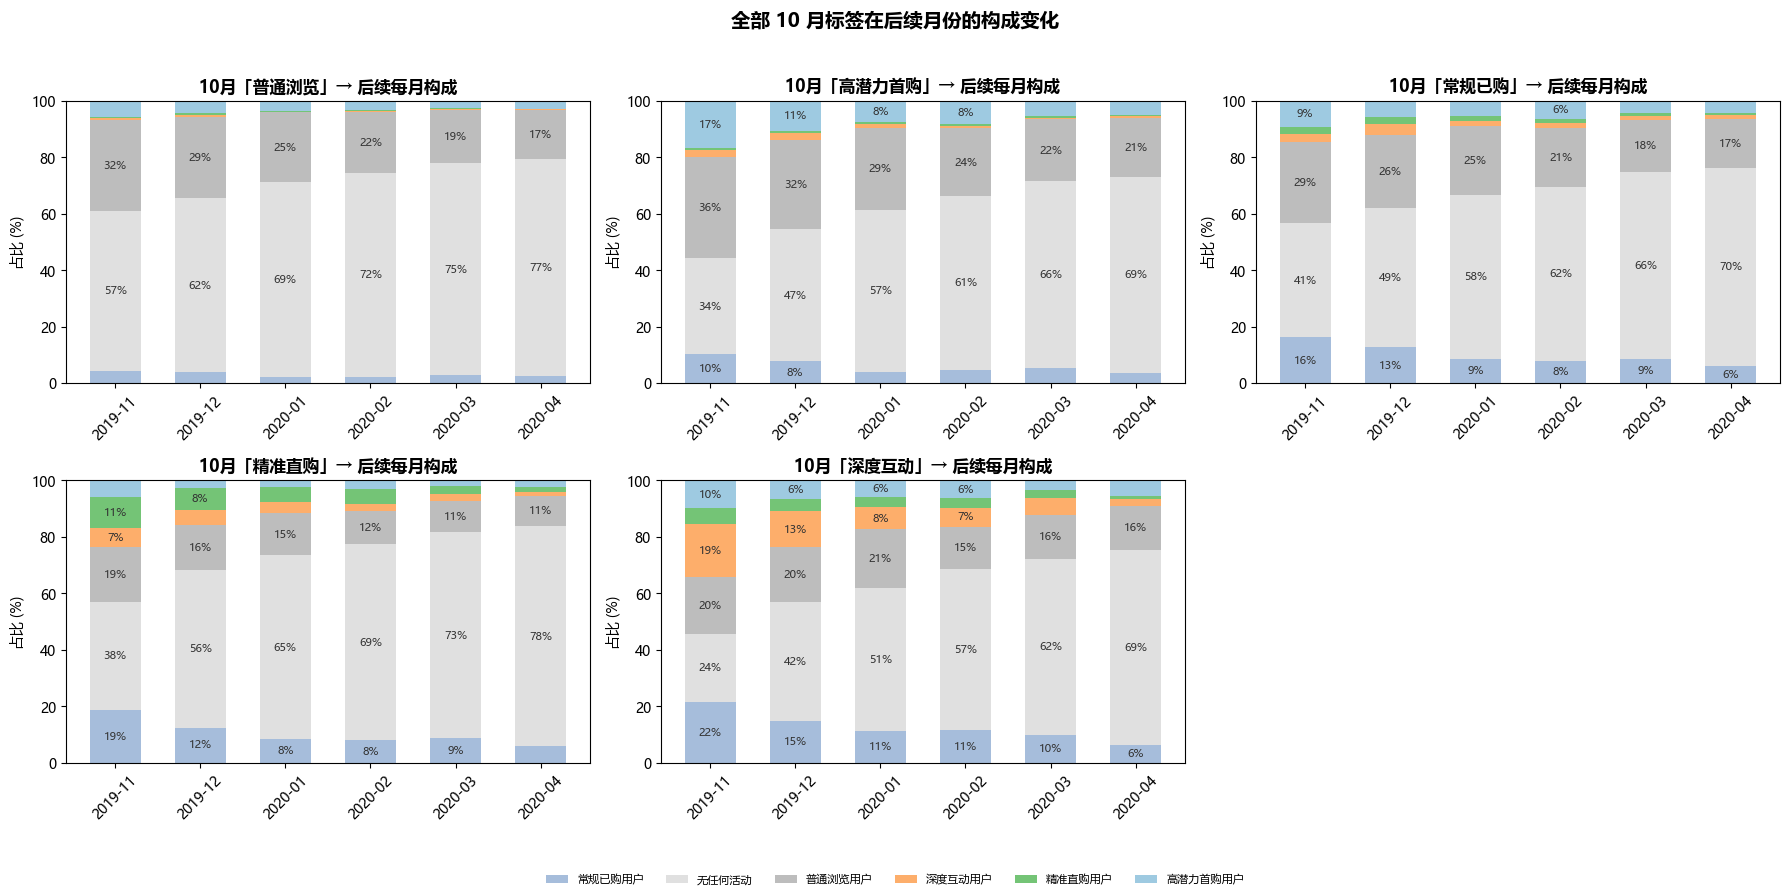

In [18]:
# ═══════════════════════════════════════════════════
# 各标签逐月构成（全部 5 个 10 月标签）
# 每个标签一张堆叠图：x = 时间（月份），堆叠 = 该月用冻结阈值重算的标签占比
# 与基期标签同色的块 = 保持原标签；浅灰 = 无任何活动；深灰/蓝 = 转化为其他标签
# ═══════════════════════════════════════════════════
import importlib
import src.config as _cfg
# 防御：kernel 早于本版本启动时，刷新配置缓存
importlib.reload(_cfg)
import src.analysis as _ana
importlib.reload(_ana)
import pandas as pd
import numpy as np
from pathlib import Path
from src.config import OUTPUT_COHORT_LABELS

# 结果文件不存在时报错退出，提示用户先跑 run_cohort.py（防御性检查）
if not Path(OUTPUT_COHORT_LABELS).exists():
    raise SystemExit(
        '未找到 cohort_frozen_labels.csv。请先运行 `python -m src.run_cohort`'
        '（需 7 个月面板，约 10-20 分钟）。')
# 读取冻结标签结果
fl = pd.read_csv(OUTPUT_COHORT_LABELS)

# 基期（10 月）的全部标签：迁移图的"出发状态"
ALL_LABELS = ['普通浏览用户', '高潜力首购用户', '常规已购用户', '精准直购用户', '深度互动用户']
# 各状态在堆叠图中的固定配色
COLOR_MAP = {
    '普通浏览用户': '#bdbdbd', '高潜力首购用户': '#9ecae1',
    '常规已购用户': '#a6bddb', '精准直购用户': '#74c476', '深度互动用户': '#fdae6b',
    '无任何活动': '#e0e0e0',
}

# 动态标签列：除了"基期标签"与"month"两列外，其余每列是一个后续月份
lab_cols = [c for c in fl.columns if c not in ('基期标签', 'month')]
# 画布：2 行 3 列（5 个标签 + 1 个空位），每个标签一张堆叠图
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

# 逐个基期标签绘制"后续每月构成"堆叠图
for i, lab in enumerate(ALL_LABELS):
    ax = axes[i]
    # 取出该基期标签的用户在后续各月的占比（按月份排序，月份为索引）
    sub = fl[fl['基期标签'] == lab].set_index('month')[lab_cols].sort_index()
    # 堆叠起点：每根柱从 0 开始，逐段累加
    bottom = np.zeros(len(sub))
    # 每个后续月份状态画一段堆叠
    for col in lab_cols:
        vals = sub[col].to_numpy() * 100
        # 画该状态在这根柱上的占比段
        ax.bar(sub.index, vals, bottom=bottom, label=col,
               color=COLOR_MAP.get(col, '#999999'), width=0.6)
        # 占比足够大的段内部标注百分比数字
        for xi, v in enumerate(vals):
            if v >= 6:
                ax.text(xi, bottom[xi] + v / 2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=8, color='#333333')
        # 把当前段高度累加进堆叠起点
        bottom += vals
    # 子图标题：10 月「该标签」→ 后续每月构成
    ax.set_title(f'10月「{lab.replace("用户", "")}」→ 后续每月构成', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.set_ylabel('占比 (%)')
    ax.tick_params(axis='x', rotation=45)
# 第 6 个位置没有数据，隐藏
axes[5].axis('off')
# 从第一张子图取图例（各子图用的状态与配色一致），统一放在图下方
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=8, frameon=False)
# 整图标题 + 为底部图例预留空间后展示
plt.suptitle('全部 10 月标签在后续月份的构成变化',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()
